In [24]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


In [25]:
# define parameters
path = 'original_data.csv'
window_size = 5
df_feature = pd.DataFrame()

In [26]:
# read data
df = pd.read_csv(path)
df_original = df[['Time', 'coe', 'Absolute_Energy']].copy()
df_original = df_original[df_original['Time'] <= 198]
df_original = df_original[df_original['coe'] >= 0]

In [27]:
#prepare a void df
df_feature = pd.DataFrame(index=range(df_original.shape[0] - window_size + 1), columns=['Time', 'coe', 'Absolute_Energy', 'culmative_Eabs'])

In [28]:
# process data
for i in range(0, df_original.shape[0] - window_size + 1):
    df_feature.loc[i, 'Time'] = max(df_original['Time'][i:i + window_size])
    df_feature.loc[i, 'coe'] = max(df_original['coe'][i:i + window_size])
    df_feature.loc[i, 'Absolute_Energy'] = max(df_original['Absolute_Energy'][i:i + window_size])


In [29]:
df_feature.tail()

,Time,coe,Absolute_Energy,culmative_Eabs
29103,197.98001,0.044224,5322.5708,NaN
29104,197.980544,0.044224,5322.5708,NaN
29105,197.986649,0.003494,5322.5708,NaN
29106,197.988021,0.003494,3966.2356,NaN
29107,197.997108,0.003494,3966.2356,NaN


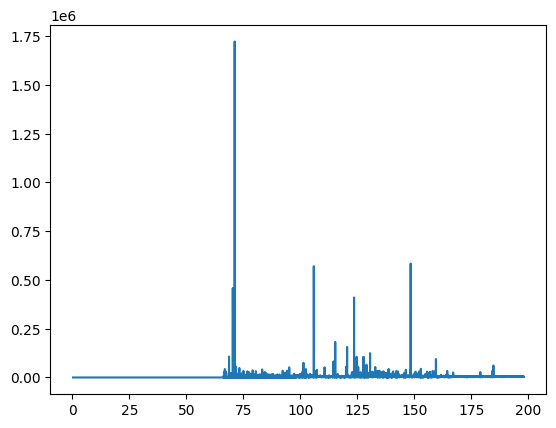

In [30]:
plt.plot(df_feature['Time'], df_feature['Absolute_Energy'])

In [31]:
for i in range(0, df_feature.shape[0]):
    df_feature['culmative_Eabs'][i] = sum(df_feature['Absolute_Energy'][0:i+1])

C:\Users\user\AppData\Local\Temp\ipykernel_28480\971664073.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_feature['culmative_Eabs'][i] = sum(df_feature['Absolute_Energy'][0:i+1])


In [32]:
df_feature.tail()

,Time,coe,Absolute_Energy,culmative_Eabs
29103,197.98001,0.044224,5322.5708,177716412.606461
29104,197.980544,0.044224,5322.5708,177721735.177261
29105,197.986649,0.003494,5322.5708,177727057.748061
29106,197.988021,0.003494,3966.2356,177731023.983661
29107,197.997108,0.003494,3966.2356,177734990.219261
